# Publication figures and a trainable CNN-quantum model

This CPU example preserves the existing text and Matplotlib workflows, exports
editable LaTeX, and displays figures directly in Notebook output cells.
The hybrid drawing explicitly describes each classical layer and batch-free tensor
shape. The declarations are checked against actual model outputs below; arbitrary
PyTorch models are not automatically traced.

Prerequisites: install this FlagQuantum checkout and Jupyter/IPython. Source export
needs no additional tools. To display the LaTeX figure, install **Tectonic** (or
TeX Live) and **Poppler** (`pdftocairo` for SVG, or `pdftoppm` for PNG) on the
Notebook kernel's PATH. For example, macOS users can run
`brew install tectonic poppler`; TeX Live plus Poppler also works on Linux.
Tectonic may download standard TeX resources on first use. FlagQuantum itself
never downloads or installs rendering executables.

In [1]:
from pathlib import Path

import torch
from torch import nn
from IPython.display import display

import flagquantum as fq
from flagquantum.drawer import ClassicalLayer, draw_hybrid

torch.manual_seed(7)
torch.set_num_threads(1)

## Existing draw behavior

The default still returns terminal text. Matplotlib still returns `(figure, axes)`;
its optional dependency is installed with `pip install "flagquantum[viz]"`.

0: ───H───╭●─┤
1: ───────╰X─┤


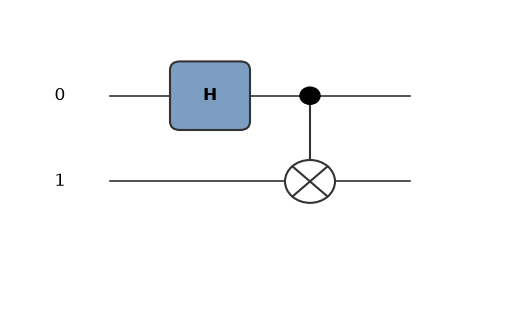

In [2]:
bell = fq.Circuit(2).h(0).cx(0, 1)
print(bell.draw())

from matplotlib import pyplot as plt

mpl_figure, axes = bell.draw(format="mpl")
display(mpl_figure)
plt.close(mpl_figure)

## Editable source and inline rendering

`format="latex"` returns a lazy `LatexFigure`. Reading `.source` or writing `.tex`
does not compile anything. Returning the object as the final expression of a cell
invokes the Notebook MIME protocol: SVG when `pdftocairo` is available, otherwise
PNG. `display=True` explicitly displays the same object.

In [3]:
symbolic = fq.Circuit(3)
for qubit in range(3):
    symbolic.ry(qubit, fq.Parameter(f"x_{qubit}"))
symbolic.cx(0, 1).cx(1, 2)
for qubit in range(3):
    symbolic.ry(qubit, fq.Parameter(f"theta_{qubit}"))

circuit_figure = symbolic.draw(format="latex")
print(circuit_figure.source)

\documentclass[border=2pt]{standalone}
\usepackage{flaghybrid}
\begin{document}
\begin{tikzpicture}
\begin{yquant}
qubit {$q_{\idx}$} q[3];
box {$R_y(x_{0})$} q[0];
box {$R_y(x_{1})$} q[1];
box {$R_y(x_{2})$} q[2];
cnot q[1] | q[0];
cnot q[2] | q[1];
box {$R_y(\theta_{0})$} q[0];
box {$R_y(\theta_{1})$} q[1];
box {$R_y(\theta_{2})$} q[2];
\end{yquant}
\end{tikzpicture}
\end{document}



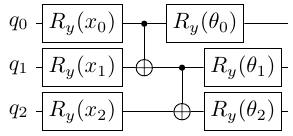

In [4]:
circuit_figure

## A real differentiable hybrid model

A small CNN maps a 1×8×8 input to three angle features. Three trainable quantum
rotations follow the entangling gates. The head maps the three Z expectations to
two class logits. One synthetic CPU training step demonstrates gradients through
all three components; it is not an accuracy or performance benchmark.

In [5]:
class HybridCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 3, kernel_size=3, padding=1),
            nn.Tanh(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        self.theta = nn.Parameter(0.1 * torch.randn(3))
        self.head = nn.Linear(3, 2)

    def quantum_features(self, features: torch.Tensor) -> torch.Tensor:
        circuit = fq.Circuit(3)
        for qubit in range(3):
            circuit.ry(qubit, features[qubit])
        circuit.cx(0, 1).cx(1, 2)
        for qubit in range(3):
            circuit.ry(qubit, self.theta[qubit])
        return torch.stack([
            circuit.expectation_z(qubit).reshape(()) for qubit in range(3)
        ])

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        features = self.encoder(images)
        quantum = torch.stack([self.quantum_features(row) for row in features])
        return self.head(quantum)


model = HybridCNN()
images = torch.randn(4, 1, 8, 8)
labels = torch.tensor([0, 1, 0, 1])
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
optimizer.zero_grad()
loss = nn.functional.cross_entropy(model(images), labels)
loss.backward()

for name, parameter in (
    ("CNN", model.encoder[0].weight),
    ("quantum", model.theta),
    ("head", model.head.weight),
):
    assert parameter.grad is not None
    assert torch.isfinite(parameter.grad).all()
    assert parameter.grad.abs().sum() > 0
    print(f"{name} gradient norm: {parameter.grad.norm().item():.6f}")

before = model.theta.detach().clone()
optimizer.step()
assert not torch.equal(before, model.theta.detach())
print(f"Synthetic training loss: {loss.detach().item():.6f}")

CNN gradient norm: 0.003033
quantum gradient norm: 0.001278
head gradient norm: 0.209511
Synthetic training loss: 0.707551


## Declare and verify the architecture

Each layer records input/output shapes without the batch dimension. The drawer
checks adjacent shapes and the readout/head boundary. We also run the actual
encoder and head below: a shape declaration alone cannot verify a Conv/Pool
operation formula. The symbolic gate sequence matches `quantum_features`.

Only Conv2d, the circuit parameters and Linear own trainable parameters. Tanh,
Pool and Flatten remain fixed transformations. Their input gradients still flow;
fixed transformations are not detached. Readout explicitly means the three Z
expectation values actually computed by the model.


The forward figure uses a compact journal-style composition, with schematic
feature-map stacks, vector glyphs and the exact eight-gate circuit on one
horizontal backbone. Glyph geometry is schematic: the numeric shapes are the
quantitative description. A star marks declared trainable components. Main-paper
artwork uses `training=False`; the real training checks above are unchanged.
The frozen example separately demonstrates the optional optimizer update paths.

The measurable reference is Nature's [official research figure guide](https://research-figure-guide.nature.com/figures/building-and-exporting-figure-panels/):
compact arrangement, black sans-serif labels, editable vector output and a
183 mm double-column width. The renderer uses 7 pt Helvetica-compatible Nimbus
Sans text, with standard mathematical notation. This is a design reference,
not journal endorsement or a guarantee of acceptance.


Conv 3x3: (1, 8, 8) -> (3, 8, 8)
Tanh: (3, 8, 8) -> (3, 8, 8)
Avg. pool: (3, 8, 8) -> (3, 1, 1)
Flatten: (3, 1, 1) -> (3,)


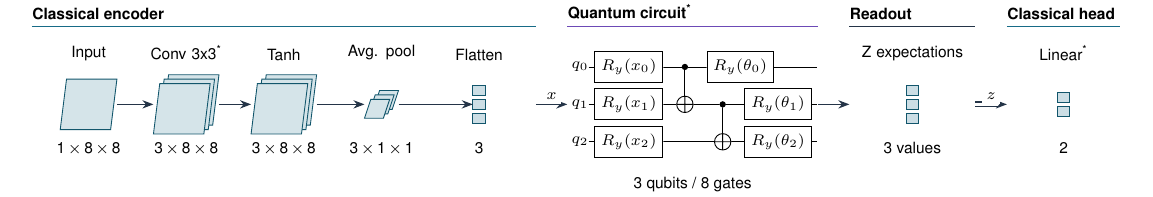

In [6]:
encoder_layers = (
    ClassicalLayer("Conv 3x3", (1, 8, 8), (3, 8, 8), trainable=True),
    ClassicalLayer("Tanh", (3, 8, 8), (3, 8, 8)),
    ClassicalLayer("Avg. pool", (3, 8, 8), (3, 1, 1)),
    ClassicalLayer("Flatten", (3, 1, 1), (3,)),
)
head_layers = (ClassicalLayer("Linear", (3,), (2,), trainable=True),)

with torch.no_grad():
    value = images[:1]
    for module, layer in zip(model.encoder, encoder_layers, strict=True):
        assert any(p.requires_grad for p in module.parameters()) == layer.trainable
        assert tuple(value.shape[1:]) == layer.input_shape
        value = module(value)
        assert tuple(value.shape[1:]) == layer.output_shape
        print(f"{layer.label}: {layer.input_shape} -> {tuple(value.shape[1:])}")
    readout = torch.stack([model.quantum_features(row) for row in value])
    assert tuple(readout.shape[1:]) == head_layers[0].input_shape
    assert tuple(model.head(readout).shape[1:]) == head_layers[0].output_shape

hybrid_figure = draw_hybrid(
    symbolic, encoder=encoder_layers, head=head_layers,
    readout="Z expectations", readout_features=readout.shape[-1],
    training=False, quantum_view="auto",
)
hybrid_figure


## Export a journal-style vector figure

The default PDF is about 182.9 mm wide including 2 pt crop margins. It fits a
183 mm double-column text area at its intended 7 pt size. Include it using a
`figure*` with `\includegraphics[width=\textwidth]{cnn-hybrid-detail.pdf}`;
do not shrink this wide figure into a single column.

The main figure uses a horizontal forward path instead of nested flowchart
cards. Short circuits are integrated at natural size. Exact tensor shapes,
readout and logits remain visible. Editable vector glyphs represent tensor
structure, not measured image activations or a reconstruction of image data.

Suggested caption (adapt to the actual experiment):

**CNN-quantum classifier.** A convolutional encoder maps a 1 x 8 x 8 input to
three angle features x. The exact circuit performs angle encoding, two
controlled-X gates and three trainable Y rotations. Its three Pauli-Z
expectations z feed a linear head with two class logits. Stars mark trainable
components. Numeric tensor shapes exclude the batch dimension; glyph geometry
is schematic. This is a synthetic differentiable example, not an accuracy
benchmark.

`.export_bundle()` includes the runtime and component licenses. The inclusion
snippet below uses the PDF directly, with its caption outside the graphic.


In [7]:
output = Path("latex_exports")
output.mkdir(exist_ok=True)
hybrid_figure.save_source(output / "cnn-hybrid-detail.tex")
main_file = hybrid_figure.export_bundle(output / "overleaf")
hybrid_figure.save(output / "cnn-hybrid-detail.pdf")
hybrid_figure.save(output / "cnn-hybrid-detail.png")
print(f"Portable project: {main_file}")


paper_source = r"""\documentclass[twocolumn]{article}
\usepackage[a4paper,margin=13.5mm]{geometry}
\usepackage{graphicx}
\begin{document}
\begin{figure*}[t]
\centering
\includegraphics[width=\textwidth]{cnn-hybrid-detail.pdf}
\caption{CNN-quantum classifier. A convolutional encoder maps an image to three
angle features $x$. The circuit performs angle encoding, two controlled-X gates
and three trainable Y rotations. Its three Pauli-Z expectations $z$ feed a linear
head with two logits. Stars mark trainable components. Numeric tensor shapes
exclude batch; glyph geometry is schematic. This is a synthetic training example.}
\end{figure*}
\end{document}
"""
(output / "paper-inclusion.tex").write_text(paper_source, encoding="utf-8")


Portable project: latex_exports/overleaf/figure.tex


638

## Freeze the encoder: verify gradients and show overview

This is an actual frozen copy of the trained model. The optimizer receives only
trainable parameters. The encoder receives no star or update arrow, while quantum and
head feedback remain. This optional training view is separate from the main
forward-only paper artwork. `overview` omits circuit detail for compact architecture
figures; it still validates the complete circuit before exporting source.


Frozen encoder: no gradients; quantum and head: finite nonzero gradients


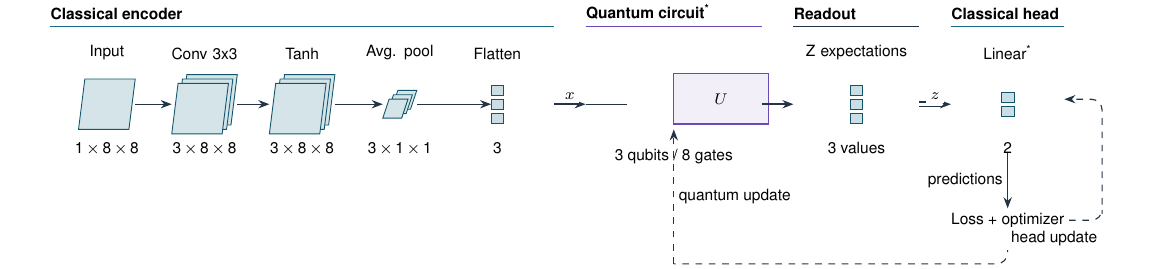

In [8]:
from copy import deepcopy

frozen_model = deepcopy(model)
frozen_model.encoder.requires_grad_(False)
frozen_optimizer = torch.optim.Adam(
    (parameter for parameter in frozen_model.parameters() if parameter.requires_grad),
    lr=0.01,
)
frozen_optimizer.zero_grad(set_to_none=True)
frozen_loss = nn.functional.cross_entropy(frozen_model(images), labels)
frozen_loss.backward()
assert all(parameter.grad is None for parameter in frozen_model.encoder.parameters())
assert frozen_model.theta.grad is not None
assert torch.isfinite(frozen_model.theta.grad).all()
assert frozen_model.theta.grad.norm() > 0
assert frozen_model.head.weight.grad is not None
assert torch.isfinite(frozen_model.head.weight.grad).all()
assert frozen_model.head.weight.grad.norm() > 0
frozen_optimizer.step()
print("Frozen encoder: no gradients; quantum and head: finite nonzero gradients")

overview = draw_hybrid(
    symbolic, encoder=encoder_layers, head=head_layers,
    readout="Z expectations", readout_features=3, training=True,
    encoder_trainable=False, quantum_view="overview",
)
assert "encoder update" not in overview.source
for extension in ("tex", "pdf", "png"):
    overview.save(output / f"cnn-hybrid-overview.{extension}")
overview


## Supplementary circuit detail

This separate layout example has 24 rotations; it is not the trained circuit
above. Auto view uses a unitary summary in panel a and the ordered circuit in
panel b. Measured panels share rows when each fits in a half-width column,
otherwise they stack without shrinking text. The four six-gate panels form a
compact two-by-two arrangement. Registers continue in order without resetting:
state this in the figure caption. The main-paper figure normally uses the compact
forward architecture; long unrolled circuits belong in supplementary material.

Rendering rejects over-wide panels or figures over 170 mm high. Reduce
`gates_per_panel`, shorten labels, summarize classical stages, choose `overview`
or split detail across separate figures. No encoding or measurement is inferred
from an arbitrary gate sequence. Source remains editable.


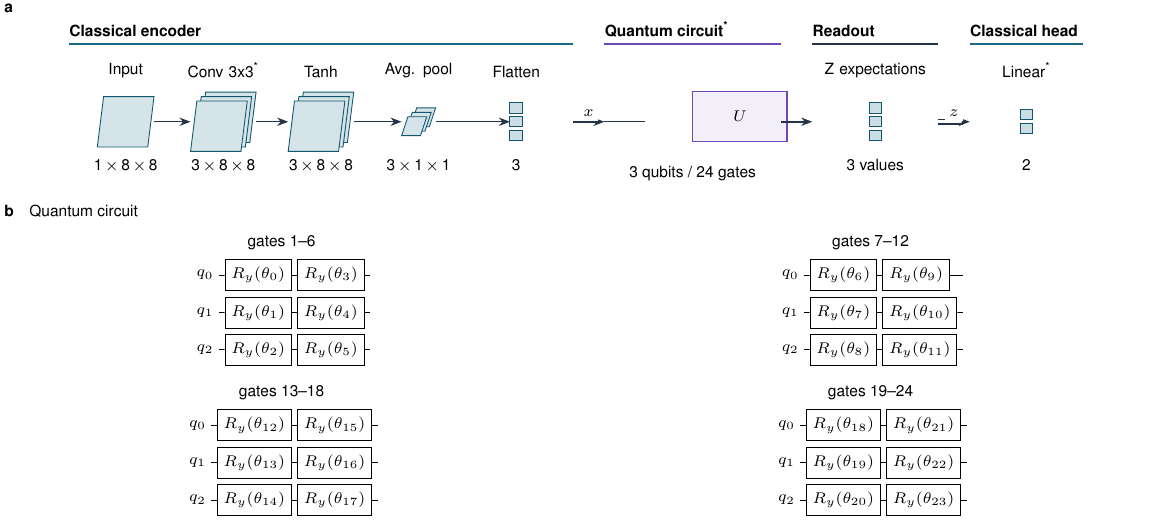

In [9]:
long_circuit = fq.Circuit(3)
for index in range(24):
    long_circuit.ry(index % 3, fq.Parameter(f"theta_{index}"))
long_figure = draw_hybrid(
    long_circuit, encoder=encoder_layers, head=head_layers,
    readout="Z expectations", readout_features=3,
    training=False, quantum_view="auto", gates_per_panel=6,
)
for extension in ("tex", "pdf", "png"):
    long_figure.save(output / f"long-circuit-hybrid.{extension}")
long_figure


## Support boundary

The drawer validates declared dimensions, not model operation formulas, encoder
mathematics, gradient correctness, arbitrary graph branches or training behavior.
This Notebook independently checks actual shapes, gradients and optimizer steps.
Readout is explicitly declared; the drawer never executes a measurement. Missing
counts and readout labels remain unspecified instead of using example defaults.
Noise channels, explicit matrices, dynamic control and batched gate parameters
still require additional rendering rules. Figure source stays editable, and
existing text/Matplotlib drawing remains available.
